# Beyond Accuracy: Benchmarking a Variational Quantum Classifier Against Classical Baselines

**Research question:** When a quantum classifier looks competitive, is the quantum component actually providing an advantage, or are we seeing an artifact of preprocessing, model capacity, or benchmark choice?

This notebook compares three classical baselines with a small 4-qubit Variational Quantum Classifier (VQC) using the same binary Iris task.

> This is a benchmarking prototype, not a claim of quantum advantage.


In [3]:
import sys
import platform

print(sys.executable)
print(platform.machine())
print(sys.version)

/Users/ann/Downloads/beyond-accuracy-qml/.venv/bin/python
arm64
3.15.0 (main, Oct  9 2026, 11:16:41) [Clang 21.0.0 (clang-2100.3.34.2)]


In [1]:
!pip -q install pennylane scikit-learn pandas matplotlib


In [4]:
import time
import numpy as onp
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

import pennylane as qml
from pennylane import numpy as np

RANDOM_STATE = 42


## 1. Dataset

We use **versicolor vs virginica** only. This gives us 100 samples and keeps all four original Iris features, which map naturally to four qubits.

Using the exact same train/test indices across all models is important for a fair comparison.


In [5]:
iris = load_iris()
X = iris.data
y = iris.target

mask = y != 0
X = X[mask]
y = (y[mask] == 2).astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train shape:", X_train_raw.shape)
print("Test shape :", X_test_raw.shape)
print("Train class balance:", onp.bincount(y_train))
print("Test class balance :", onp.bincount(y_test))


Train shape: (70, 4)
Test shape : (30, 4)
Train class balance: [35 35]
Test class balance : [15 15]


## 2. Classical baselines

All classical models receive the same training and test examples. We deliberately include:
- a linear model,
- a strong nonlinear kernel method,
- a small neural network.


In [6]:
classical_models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "RBF SVM": Pipeline([
        ("scale", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=1.0, gamma="scale"))
    ]),
    "Small MLP": Pipeline([
        ("scale", StandardScaler()),
        ("clf", MLPClassifier(
            hidden_layer_sizes=(8,),
            max_iter=3000,
            random_state=RANDOM_STATE,
            alpha=1e-3
        ))
    ])
}

rows = []

for name, model in classical_models.items():
    t0 = time.perf_counter()
    model.fit(X_train_raw, y_train)
    elapsed = time.perf_counter() - t0

    pred = model.predict(X_test_raw)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred)

    if name == "Logistic Regression":
        clf = model.named_steps["clf"]
        n_params = clf.coef_.size + clf.intercept_.size
    elif name == "Small MLP":
        clf = model.named_steps["clf"]
        n_params = sum(w.size for w in clf.coefs_) + sum(b.size for b in clf.intercepts_)
    else:
        n_params = onp.nan

    rows.append({
        "Model": name,
        "Test Accuracy": acc,
        "F1 Score": f1,
        "Training Time (s)": elapsed,
        "Trainable Parameters": n_params,
        "Quantum Circuit Evaluations": 0
    })

classical_results = pd.DataFrame(rows)
classical_results


,Model,Test Accuracy,F1 Score,Training Time (s),Trainable Parameters,Quantum Circuit Evaluations
0,Logistic Regression,0.9,0.896552,0.108243,5.0,0
1,RBF SVM,0.9,0.896552,0.004248,NaN,0
2,Small MLP,0.9,0.896552,0.119359,49.0,0


## 3. Prepare the same data for quantum angle encoding

The train/test examples remain identical. We standardize using statistics learned from the training set, then map the four features into `[-pi, pi]` so they can be used as rotation angles.

This extra encoding step is part of the QML pipeline and should not be ignored when discussing end-to-end cost.


In [7]:
standardizer = StandardScaler()
X_train_std = standardizer.fit_transform(X_train_raw)
X_test_std = standardizer.transform(X_test_raw)

angle_scaler = MinMaxScaler(feature_range=(-onp.pi, onp.pi))
X_train_q = angle_scaler.fit_transform(X_train_std)
X_test_q = angle_scaler.transform(X_test_std)

X_train_q = np.array(X_train_q, requires_grad=False)
X_test_q = np.array(X_test_q, requires_grad=False)
y_train_q = np.array(y_train, requires_grad=False)


## 4. Build a 4-qubit VQC

The circuit has:
- 4 qubits,
- angle encoding with `RY`,
- trainable `RY` layers,
- a CNOT ring for entanglement,
- one Pauli-Z expectation value as the prediction signal.

We keep it intentionally small so the experiment is easy to inspect and reproduce.


In [8]:
n_qubits = 4
n_layers = 2

# Analytic simulator for the main run.
dev = qml.device("default.qubit", wires=n_qubits, shots=None)

eval_counter = {"count": 0}

@qml.qnode(dev, interface="autograd")
def quantum_circuit(x, weights):
    eval_counter["count"] += 1

    qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Y")

    for l in range(n_layers):
        for q in range(n_qubits):
            qml.RY(weights[l, q], wires=q)

        for q in range(n_qubits - 1):
            qml.CNOT(wires=[q, q + 1])
        qml.CNOT(wires=[n_qubits - 1, 0])

    return qml.expval(qml.PauliZ(0))

print(qml.draw(quantum_circuit)(
    X_train_q[0],
    np.zeros((n_layers, n_qubits), requires_grad=True)
))


0: ─╭AngleEmbedding(M0)──RY(0.00)─╭●───────╭X──RY(0.00)─╭●───────╭X─┤  <Z>
1: ─├AngleEmbedding(M0)──RY(0.00)─╰X─╭●────│───RY(0.00)─╰X─╭●────│──┤     
2: ─├AngleEmbedding(M0)──RY(0.00)────╰X─╭●─│───RY(0.00)────╰X─╭●─│──┤     
3: ─╰AngleEmbedding(M0)──RY(0.00)───────╰X─╰●──RY(0.00)───────╰X─╰●─┤     

M0 = 
[-0.44879895  1.57079633  1.04719755  2.72271363]


## 5. Train the VQC

The Pauli-Z expectation value lies in `[-1, 1]`, so we map it to a pseudo-probability in `[0, 1]`.

For a small demo, we optimize binary cross-entropy using Adam. The number of epochs is deliberately modest so the notebook can run quickly.


In [9]:
def probability(x, weights):
    z = quantum_circuit(x, weights)
    return (z + 1.0) / 2.0

def binary_cross_entropy(weights, X_batch, y_batch):
    eps = 1e-8
    probs = np.stack([probability(x, weights) for x in X_batch])
    probs = np.clip(probs, eps, 1.0 - eps)
    return -np.mean(y_batch * np.log(probs) + (1 - y_batch) * np.log(1 - probs))

rng = onp.random.default_rng(RANDOM_STATE)
weights = np.array(
    0.01 * rng.standard_normal((n_layers, n_qubits)),
    requires_grad=True
)

optimizer = qml.AdamOptimizer(stepsize=0.08)

epochs = 30
loss_history = []
eval_counter["count"] = 0

t0 = time.perf_counter()

for epoch in range(epochs):
    weights, loss = optimizer.step_and_cost(
        lambda w: binary_cross_entropy(w, X_train_q, y_train_q),
        weights
    )
    loss_history.append(float(loss))

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:02d}/{epochs} | loss = {float(loss):.4f}")

vqc_training_time = time.perf_counter() - t0
vqc_evaluations = eval_counter["count"]

print("Training time:", round(vqc_training_time, 3), "s")
print("Circuit evaluations:", vqc_evaluations)


Epoch 05/30 | loss = 0.6581
Epoch 10/30 | loss = 0.5953
Epoch 15/30 | loss = 0.5485
Epoch 20/30 | loss = 0.5367
Epoch 25/30 | loss = 0.5202
Epoch 30/30 | loss = 0.5024
Training time: 18.922 s
Circuit evaluations: 2100


## 6. Evaluate the VQC


In [10]:
test_probs = onp.array([
    float(probability(x, weights))
    for x in X_test_q
])

vqc_pred = (test_probs >= 0.5).astype(int)

vqc_accuracy = accuracy_score(y_test, vqc_pred)
vqc_f1 = f1_score(y_test, vqc_pred)

print("VQC test accuracy:", vqc_accuracy)
print("VQC F1 score:", vqc_f1)


VQC test accuracy: 0.7333333333333333
VQC F1 score: 0.6923076923076923


## 7. Compare performance *and* cost

The important point is not whether the VQC wins one accuracy number. We want to see what it costs to obtain that performance.

For a real hardware experiment, we would also include:
- number of shots,
- queue / communication latency,
- hardware noise,
- circuit depth,
- transpiled two-qubit gate count.


In [11]:
vqc_row = pd.DataFrame([{
    "Model": "4-qubit VQC",
    "Test Accuracy": vqc_accuracy,
    "F1 Score": vqc_f1,
    "Training Time (s)": vqc_training_time,
    "Trainable Parameters": n_layers * n_qubits,
    "Quantum Circuit Evaluations": vqc_evaluations
}])

all_results = pd.concat([classical_results, vqc_row], ignore_index=True)
all_results


,Model,Test Accuracy,F1 Score,Training Time (s),Trainable Parameters,Quantum Circuit Evaluations
0,Logistic Regression,0.900000,0.896552,0.108243,5.0,0
1,RBF SVM,0.900000,0.896552,0.004248,NaN,0
2,Small MLP,0.900000,0.896552,0.119359,49.0,0
3,4-qubit VQC,0.733333,0.692308,18.922185,8.0,2100


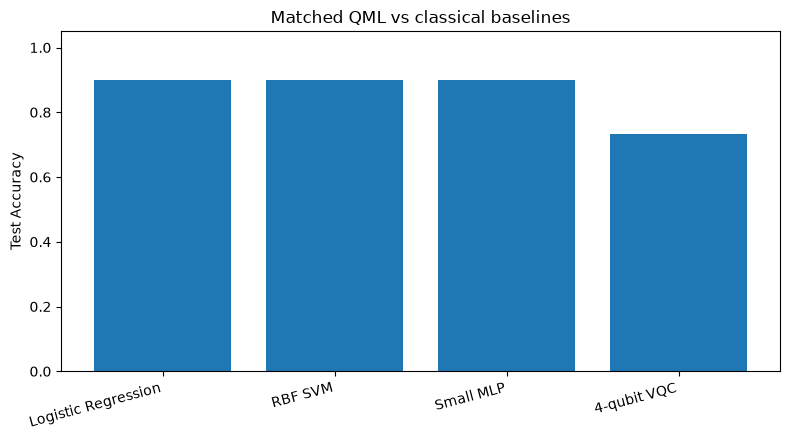

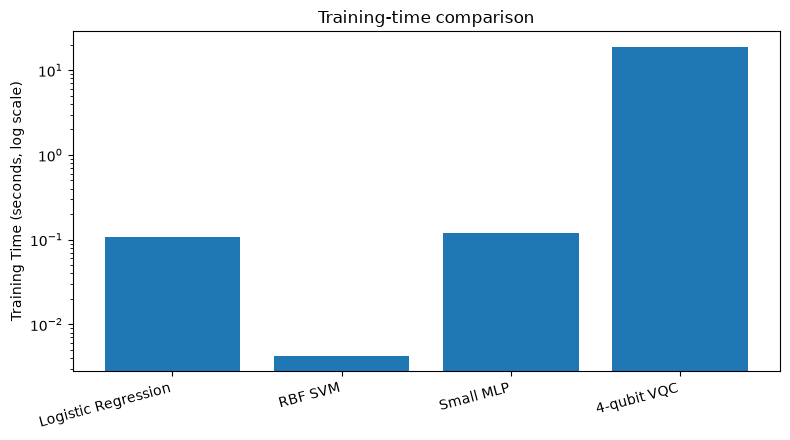

In [12]:
plt.figure(figsize=(8, 4.5))
plt.bar(all_results["Model"], all_results["Test Accuracy"])
plt.ylim(0, 1.05)
plt.ylabel("Test Accuracy")
plt.title("Matched QML vs classical baselines")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.bar(all_results["Model"], all_results["Training Time (s)"])
plt.yscale("log")
plt.ylabel("Training Time (seconds, log scale)")
plt.title("Training-time comparison")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


## 8. Optional: finite-shot sanity check

The main run above uses an analytic simulator. Real quantum hardware estimates expectation values from finite measurements.

This optional cell re-evaluates the trained circuit with a finite number of shots. It is not a full noise study, but it shows how measurement sampling enters the pipeline.


In [14]:
shots = 1000
shot_dev = qml.device("default.qubit", wires=n_qubits, shots=shots)

@qml.qnode(shot_dev)
def shot_circuit(x, weights):
    qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Y")
    for l in range(n_layers):
        for q in range(n_qubits):
            qml.RY(weights[l, q], wires=q)
        for q in range(n_qubits - 1):
            qml.CNOT(wires=[q, q + 1])
        qml.CNOT(wires=[n_qubits - 1, 0])
    return qml.expval(qml.PauliZ(0))

shot_probs = onp.array([
    (float(shot_circuit(x, weights)) + 1.0) / 2.0
    for x in X_test_q
])

shot_pred = (shot_probs >= 0.5).astype(int)

print("Finite-shot accuracy:", accuracy_score(y_test, shot_pred))
print("Shots per inference circuit:", shots)
print("Approximate test-set shots:", shots * len(X_test_q))


Finite-shot accuracy: 0.7333333333333333
Shots per inference circuit: 1000
Approximate test-set shots: 30000


/Users/ann/Downloads/beyond-accuracy-qml/.venv/lib/python3.15/site-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


## 9. Interpretation

A result from this notebook should be phrased cautiously.

A suitable conclusion would be:

> On this small classical dataset, the VQC can be benchmarked fairly against classical models when the data split is held fixed and end-to-end costs are reported. Whether it matches or loses to the baselines is not evidence for or against QML in general. The more important result is that accuracy alone is insufficient for a quantum-advantage claim.

### Questions for the next iteration

- Does increasing circuit depth improve accuracy enough to justify its cost?
- Does the conclusion change across random seeds?
- What happens under finite-shot and hardware-inspired noise?
- Would a quantum kernel offer a more meaningful comparison?
- Can we design a task where the feature map is classically difficult to reproduce?
- Does the problem become more natural when the input data are quantum rather than classical?
